Nima Rezaei – 401130373

Arman Esmaeili - 401130133

# **1) Facades dataset + build (corrupted → clean) pairs**



*   **Download + extract**



In [3]:
!wget -q http://efrosgans.eecs.berkeley.edu/pix2pix/datasets/facades.tar.gz
!tar -xzf facades.tar.gz
!ls facades

test  train  val




*   **Dataset class (split halves + create corruption)**


In [4]:
import os, glob
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

class FacadesInpaintingDataset(Dataset):
    def __init__(self, root="facades/train", image_size=256, min_hole=32, max_hole=96):
        self.paths = sorted(glob.glob(os.path.join(root, "*.jpg")))
        self.image_size = image_size
        self.min_hole = min_hole
        self.max_hole = max_hole

        # Pix2Pix standard: scale to [-1, 1]
        self.tf = T.Compose([
            T.Resize((image_size, image_size)),
            T.ToTensor(),
            T.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
        ])

    def _split_AB(self, img):
        # img: PIL image, width is typically 2*H
        w, h = img.size
        w2 = w // 2
        A = img.crop((0, 0, w2, h))
        B = img.crop((w2, 0, w, h))
        return A, B

    def _random_rect_mask(self, H, W):
        mask = torch.ones(1, H, W)
        hole = torch.randint(self.min_hole, self.max_hole + 1, (1,)).item()
        x = torch.randint(0, W - hole, (1,)).item()
        y = torch.randint(0, H - hole, (1,)).item()
        mask[:, y:y+hole, x:x+hole] = 0.0
        return mask

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        _, B = self._split_AB(img)         # we use B as the clean target
        clean = self.tf(B)                 # (3,H,W) in [-1,1]

        # create mask in tensor space
        _, H, W = clean.shape
        mask = self._random_rect_mask(H, W)            # (1,H,W) with 1=keep, 0=hole

        corrupted = clean * mask                        # hole becomes 0 (in [-1,1] space)

        # input = [corrupted_rgb, mask] => 4 channels
        inp = torch.cat([corrupted, mask], dim=0)       # (4,H,W)
        return inp, clean




*   **DataLoaders + sanity visualization**



In [5]:
import matplotlib.pyplot as plt

batch_size = 16
train_ds = FacadesInpaintingDataset("facades/train")
test_ds  = FacadesInpaintingDataset("facades/test")

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

x, y = next(iter(train_loader))
print("Input batch:", x.shape)   # expected: [B, 4, 256, 256]
print("Target batch:", y.shape)  # expected: [B, 3, 256, 256]

Input batch: torch.Size([16, 4, 256, 256])
Target batch: torch.Size([16, 3, 256, 256])




*   **Plot a few samples (corrupted vs clean)**

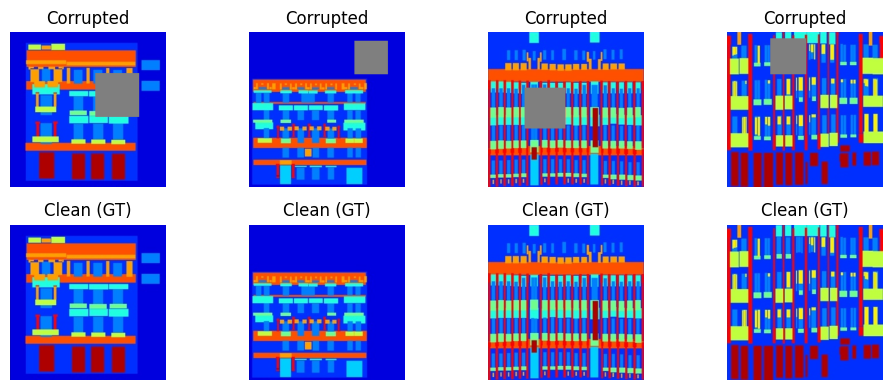

In [6]:
def denorm(img):
    # img in [-1,1] -> [0,1]
    return (img * 0.5 + 0.5).clamp(0,1)

x, y = next(iter(train_loader))

plt.figure(figsize=(10,4))
for i in range(4):
    corrupted_rgb = denorm(x[i, :3])  # first 3 channels
    clean_rgb = denorm(y[i])

    plt.subplot(2,4,i+1)
    plt.imshow(corrupted_rgb.permute(1,2,0))
    plt.title("Corrupted")
    plt.axis("off")

    plt.subplot(2,4,i+5)
    plt.imshow(clean_rgb.permute(1,2,0))
    plt.title("Clean (GT)")
    plt.axis("off")

plt.tight_layout()
plt.show()


# **2) Pix2Pix (U-Net G + PatchGAN D) exactly**



*   **Generator (U-Net)**

      - Input channels = 4 (RGB + mask)

      - Output channels = 3 (restored RGB)

      - Output activation = tanh (because we normalized images to [-1, 1])


In [7]:
import torch
import torch.nn as nn

class UNetDown(nn.Module):
    def __init__(self, in_c, out_c, normalize=True, dropout=0.0):
        super().__init__()
        layers = [nn.Conv2d(in_c, out_c, 4, 2, 1, bias=False)]
        if normalize:
            layers.append(nn.BatchNorm2d(out_c))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

class UNetUp(nn.Module):
    def __init__(self, in_c, out_c, dropout=0.0):
        super().__init__()
        layers = [
            nn.ConvTranspose2d(in_c, out_c, 4, 2, 1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        ]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x, skip):
        x = self.model(x)
        return torch.cat((x, skip), dim=1)

class GeneratorUNet(nn.Module):
    def __init__(self, in_channels=4, out_channels=3):
        super().__init__()

        # Downsampling
        self.d1 = UNetDown(in_channels, 64, normalize=False)   # 256 -> 128
        self.d2 = UNetDown(64, 128)                            # 128 -> 64
        self.d3 = UNetDown(128, 256)                           # 64 -> 32
        self.d4 = UNetDown(256, 512, dropout=0.0)              # 32 -> 16
        self.d5 = UNetDown(512, 512, dropout=0.0)              # 16 -> 8
        self.d6 = UNetDown(512, 512, dropout=0.0)              # 8 -> 4
        self.d7 = UNetDown(512, 512, dropout=0.0)              # 4 -> 2
        self.d8 = UNetDown(512, 512, normalize=False)          # 2 -> 1

        # Upsampling
        self.u1 = UNetUp(512, 512, dropout=0.0)                # 1 -> 2
        self.u2 = UNetUp(1024, 512, dropout=0.0)               # 2 -> 4
        self.u3 = UNetUp(1024, 512, dropout=0.0)               # 4 -> 8
        self.u4 = UNetUp(1024, 512, dropout=0.0)               # 8 -> 16
        self.u5 = UNetUp(1024, 256, dropout=0.0)               # 16 -> 32
        self.u6 = UNetUp(512, 128, dropout=0.0)                # 32 -> 64
        self.u7 = UNetUp(256, 64, dropout=0.0)                 # 64 -> 128

        self.final = nn.Sequential(
            nn.ConvTranspose2d(128, out_channels, 4, 2, 1),    # 128 -> 256
            nn.Tanh()
        )

    def forward(self, x):
        d1 = self.d1(x)
        d2 = self.d2(d1)
        d3 = self.d3(d2)
        d4 = self.d4(d3)
        d5 = self.d5(d4)
        d6 = self.d6(d5)
        d7 = self.d7(d6)
        d8 = self.d8(d7)

        u1 = self.u1(d8, d7)
        u2 = self.u2(u1, d6)
        u3 = self.u3(u2, d5)
        u4 = self.u4(u3, d4)
        u5 = self.u5(u4, d3)
        u6 = self.u6(u5, d2)
        u7 = self.u7(u6, d1)

        return self.final(u7)




*   **Discriminator (PatchGAN)**
      - Discriminator input is concatenation of (condition image, target image)

      - Here: condition has 4 channels, target has 3 → total = 7 channels

      - Output is a grid of real/fake scores (“PatchGAN”)


In [8]:
class Discriminator(nn.Module):
    def __init__(self, in_channels=7):
        super().__init__()

        def block(in_c, out_c, normalize=True):
            layers = [nn.Conv2d(in_c, out_c, 4, 2, 1, bias=False)]
            if normalize:
                layers.append(nn.BatchNorm2d(out_c))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *block(in_channels, 64, normalize=False),  # 256 -> 128
            *block(64, 128),                           # 128 -> 64
            *block(128, 256),                          # 64 -> 32
            *block(256, 512),                          # 32 -> 16
            nn.Conv2d(512, 1, 4, 1, 1)                 # 16 -> 15 (patch map)
        )

    def forward(self, cond, img):
        x = torch.cat([cond, img], dim=1)
        return self.model(x)




*   **Losses + Optimizers (Pix2Pix standard)**
      - GAN loss: BCEWithLogitsLoss

      - L1 loss with λ = 100

      - Optim: Adam(lr=2e-4, betas=(0.5,0.999))



In [9]:
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

G = GeneratorUNet(in_channels=4, out_channels=3).to(device)
D = Discriminator(in_channels=7).to(device)

gan_loss = nn.BCEWithLogitsLoss()
l1_loss = nn.L1Loss()
lambda_l1 = 100

opt_G = optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))




*   **Sanity check forward pass**


In [10]:
x, y = next(iter(train_loader))
x, y = x.to(device), y.to(device)

fake = G(x)
print("fake shape:", fake.shape)          # (B,3,256,256)

pred_real = D(x, y)
pred_fake = D(x, fake.detach())
print("D(real) shape:", pred_real.shape)  # (B,1,?,?)
print("D(fake) shape:", pred_fake.shape)


fake shape: torch.Size([16, 3, 256, 256])
D(real) shape: torch.Size([16, 1, 15, 15])
D(fake) shape: torch.Size([16, 1, 15, 15])


# **3) Training Pix2Pix (cGAN) + visuals + PSNR/SSIM**



*   **Helper: denorm + sample visualization function**
    - This will show: Corrupted | Generated | Ground Truth.



In [11]:
import matplotlib.pyplot as plt
import torch

def denorm(x):
    # [-1,1] -> [0,1]
    return (x * 0.5 + 0.5).clamp(0, 1)

@torch.no_grad()
def show_triplet(G, loader, device, n=4):
    G.eval()
    x, y = next(iter(loader))
    x, y = x.to(device), y.to(device)
    fake = G(x)

    plt.figure(figsize=(12, 3*n))
    for i in range(n):
        corrupted = denorm(x[i, :3]).permute(1,2,0).cpu()
        generated = denorm(fake[i]).permute(1,2,0).cpu()
        gt = denorm(y[i]).permute(1,2,0).cpu()

        plt.subplot(n, 3, 3*i + 1)
        plt.imshow(corrupted)
        plt.title("Corrupted (Input)")
        plt.axis("off")

        plt.subplot(n, 3, 3*i + 2)
        plt.imshow(generated)
        plt.title("Generated (Restored)")
        plt.axis("off")

        plt.subplot(n, 3, 3*i + 3)
        plt.imshow(gt)
        plt.title("Ground Truth")
        plt.axis("off")

    plt.tight_layout()
    plt.show()




*   We can call show_triplet(G, test_loader, device) any time (even before training) to see random outputs.




*   **Training step functions (D step + G step)**


In [12]:
def train_one_epoch_pix2pix(G, D, loader, opt_G, opt_D, gan_loss, l1_loss, lambda_l1, device):
    G.train()
    D.train()

    g_running, d_running = 0.0, 0.0
    n_samples = 0

    for cond, real in loader:
        cond, real = cond.to(device), real.to(device)
        B = cond.size(0)
        n_samples += B

        # --------------------
        # Train Discriminator
        # --------------------
        fake = G(cond)

        pred_real = D(cond, real)
        pred_fake = D(cond, fake.detach())

        real_targets = torch.ones_like(pred_real)
        fake_targets = torch.zeros_like(pred_fake)

        d_loss_real = gan_loss(pred_real, real_targets)
        d_loss_fake = gan_loss(pred_fake, fake_targets)
        d_loss = (d_loss_real + d_loss_fake) * 0.5

        opt_D.zero_grad()
        d_loss.backward()
        opt_D.step()

        # ----------------
        # Train Generator
        # ----------------
        pred_fake_for_G = D(cond, fake)
        g_gan = gan_loss(pred_fake_for_G, torch.ones_like(pred_fake_for_G))
        g_l1 = l1_loss(fake, real) * lambda_l1
        g_loss = g_gan + g_l1

        opt_G.zero_grad()
        g_loss.backward()
        opt_G.step()

        d_running += d_loss.item() * B
        g_running += g_loss.item() * B

    return d_running / n_samples, g_running / n_samples




*   **PSNR / SSIM evaluation**
    - We’ll compute on the test set in [0,1] space.


In [13]:
import numpy as np
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

@torch.no_grad()
def evaluate_psnr_ssim(G, loader, device):
    G.eval()

    total_psnr = 0
    total_ssim = 0
    count = 0

    for cond, real in loader:
        cond, real = cond.to(device), real.to(device)
        fake = G(cond)

        fake01 = denorm(fake).cpu().numpy()
        real01 = denorm(real).cpu().numpy()

        for i in range(fake01.shape[0]):
            f = np.transpose(fake01[i], (1,2,0))
            r = np.transpose(real01[i], (1,2,0))

            total_psnr += peak_signal_noise_ratio(r, f, data_range=1.0)
            total_ssim += structural_similarity(r, f, channel_axis=2, data_range=1.0)
            count += 1

    return total_psnr / count, total_ssim / count


*   **Full training loop (with plots + sample outputs per epoch)**



In [14]:
torch.backends.cudnn.benchmark = True

Epoch 01/20 | D_loss: 0.5523 | G_loss: 31.2630 | PSNR: 16.32 | SSIM: 0.3127
Epoch 02/20 | D_loss: 0.5493 | G_loss: 14.0224 | PSNR: 18.19 | SSIM: 0.5747
Epoch 03/20 | D_loss: 0.5731 | G_loss: 12.3239 | PSNR: 17.86 | SSIM: 0.6199
Epoch 04/20 | D_loss: 0.5421 | G_loss: 11.1511 | PSNR: 20.68 | SSIM: 0.6874
Epoch 05/20 | D_loss: 0.6090 | G_loss: 9.8300 | PSNR: 21.44 | SSIM: 0.7295


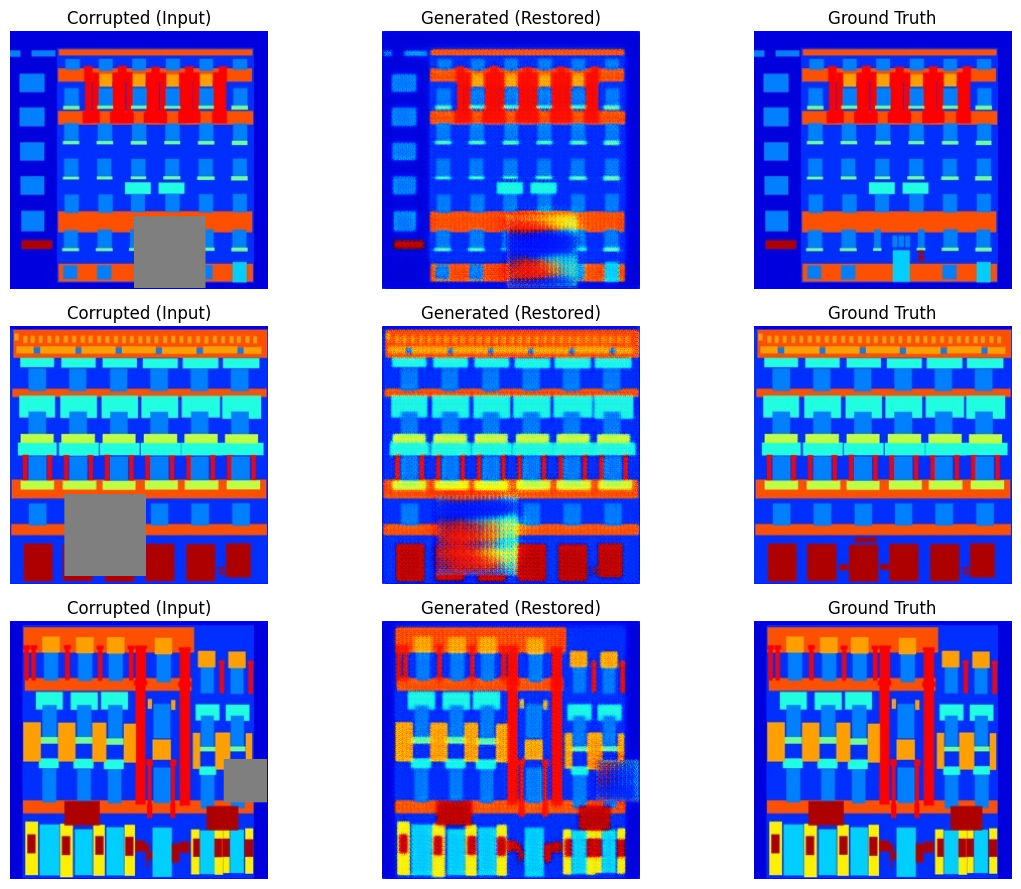

Epoch 06/20 | D_loss: 0.5861 | G_loss: 9.2903 | PSNR: 21.17 | SSIM: 0.7354
Epoch 07/20 | D_loss: 0.6071 | G_loss: 9.2997 | PSNR: 21.30 | SSIM: 0.7673
Epoch 08/20 | D_loss: 0.6021 | G_loss: 8.9578 | PSNR: 21.88 | SSIM: 0.7566
Epoch 09/20 | D_loss: 0.6220 | G_loss: 8.5290 | PSNR: 21.90 | SSIM: 0.7864
Epoch 10/20 | D_loss: 0.5991 | G_loss: 8.2469 | PSNR: 22.42 | SSIM: 0.7883


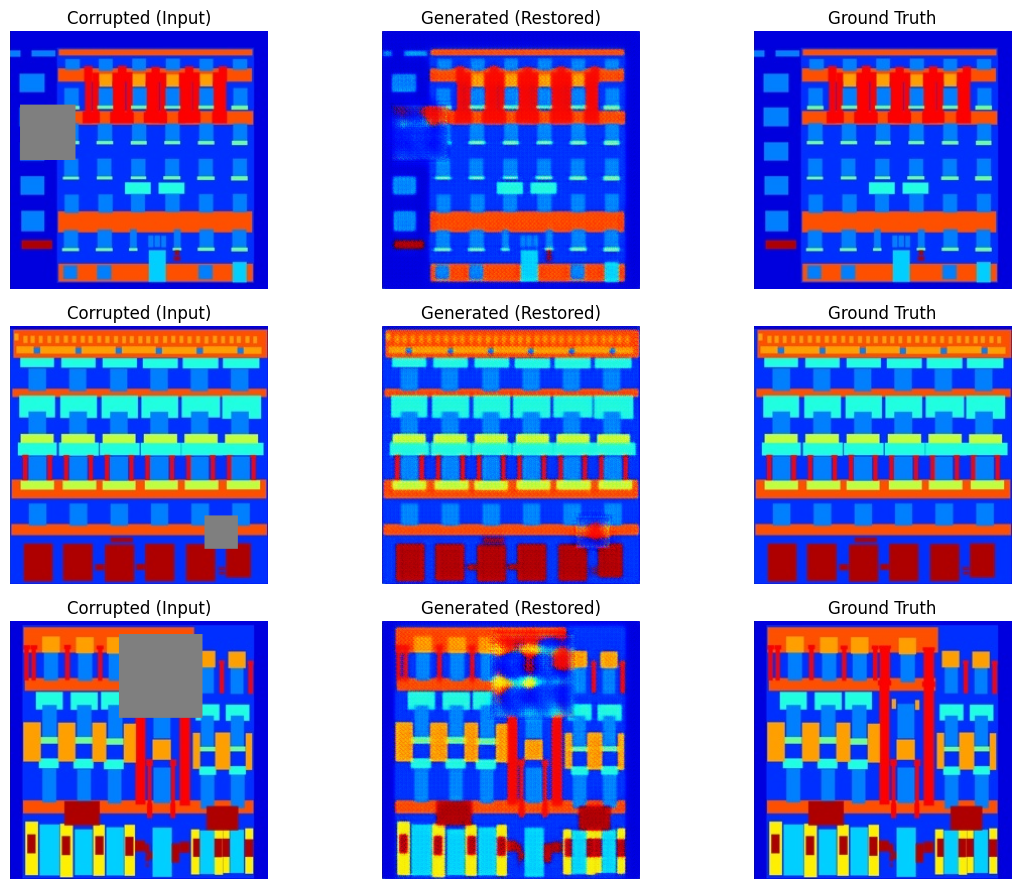

Epoch 11/20 | D_loss: 0.5688 | G_loss: 8.3263 | PSNR: 21.64 | SSIM: 0.7687
Epoch 12/20 | D_loss: 0.6067 | G_loss: 8.3204 | PSNR: 22.39 | SSIM: 0.7976
Epoch 13/20 | D_loss: 0.5714 | G_loss: 8.0658 | PSNR: 21.92 | SSIM: 0.7724
Epoch 14/20 | D_loss: 0.6147 | G_loss: 7.7025 | PSNR: 21.88 | SSIM: 0.8054
Epoch 15/20 | D_loss: 0.5907 | G_loss: 7.6505 | PSNR: 22.85 | SSIM: 0.8023


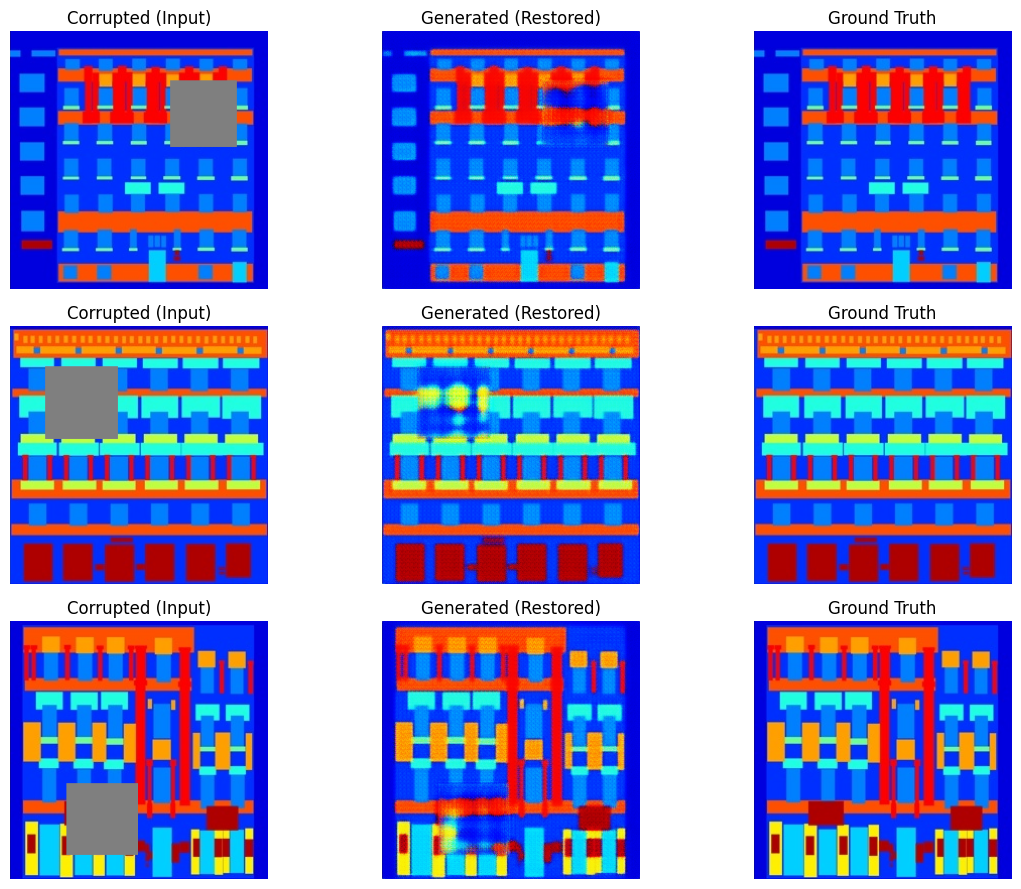

Epoch 16/20 | D_loss: 0.5723 | G_loss: 7.6376 | PSNR: 22.42 | SSIM: 0.7934
Epoch 17/20 | D_loss: 0.5787 | G_loss: 7.5037 | PSNR: 22.58 | SSIM: 0.8055
Epoch 18/20 | D_loss: 0.5638 | G_loss: 7.5449 | PSNR: 22.22 | SSIM: 0.8010
Epoch 19/20 | D_loss: 0.5628 | G_loss: 7.6009 | PSNR: 22.76 | SSIM: 0.8057
Epoch 20/20 | D_loss: 0.5771 | G_loss: 7.3762 | PSNR: 22.97 | SSIM: 0.8174


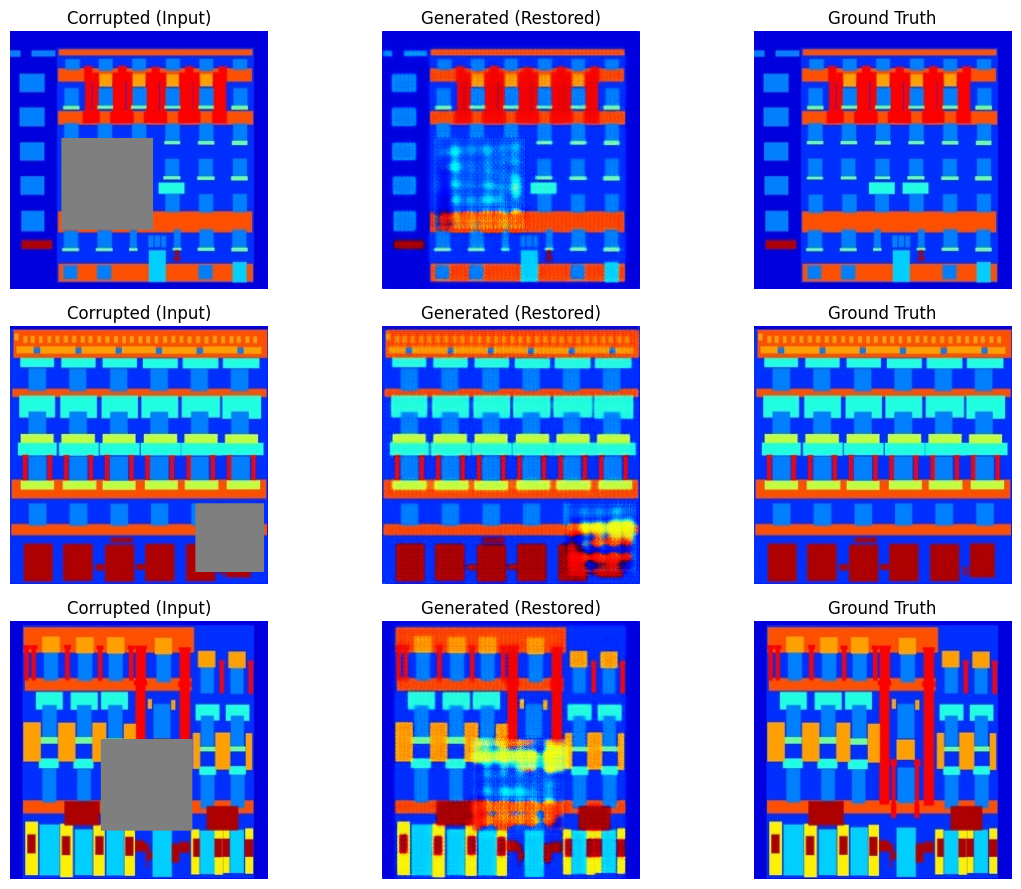

In [15]:
num_epochs = 20

history = {
    "d_loss": [],
    "g_loss": [],
    "psnr": [],
    "ssim": []
}

for epoch in range(1, num_epochs + 1):
    d_loss, g_loss = train_one_epoch_pix2pix(
        G, D, train_loader, opt_G, opt_D,
        gan_loss, l1_loss, lambda_l1, device
    )

    psnr, ssim = evaluate_psnr_ssim(G, test_loader, device)

    history["d_loss"].append(d_loss)
    history["g_loss"].append(g_loss)
    history["psnr"].append(psnr)
    history["ssim"].append(ssim)

    print(f"Epoch {epoch:02d}/{num_epochs} | D_loss: {d_loss:.4f} | G_loss: {g_loss:.4f} | PSNR: {psnr:.2f} | SSIM: {ssim:.4f}")

    # Show qualitative results every few epochs
    if epoch % 5 == 0:
        show_triplet(G, test_loader, device, n=3)


In [16]:
torch.save(G.state_dict(), "best_generator.pth")
print("Saved: best_generator.pth")

Saved: best_generator.pth




*   Load model



In [17]:
ckpt_path = "best_generator.pth"

G.load_state_dict(torch.load(ckpt_path, map_location=device))
G.eval()
print("Generator loaded successfully!")

Generator loaded successfully!


In [18]:
import numpy as np

def tensor_to_uint8(img_t):
    # img_t: (3,H,W) in [-1,1]
    img = (img_t * 0.5 + 0.5).clamp(0,1)         # -> [0,1]
    img = (img.permute(1,2,0).cpu().numpy() * 255).astype(np.uint8)
    return img

In [19]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

def calc_psnr_ssim(gt_uint8, pred_uint8):
    psnr = peak_signal_noise_ratio(gt_uint8, pred_uint8, data_range=255)
    ssim = structural_similarity(gt_uint8, pred_uint8, channel_axis=2, data_range=255)
    return float(psnr), float(ssim)

*   Slider for size of mask




In [20]:
import torch

def apply_center_mask(clean_img, hole_size):
    # clean_img: (3,H,W) in [-1,1]
    _, H, W = clean_img.shape
    mask = torch.ones((1, H, W), device=clean_img.device)

    hole = int(hole_size)
    y = (H - hole) // 2
    x = (W - hole) // 2

    mask[:, y:y+hole, x:x+hole] = 0.0
    corrupted = clean_img * mask
    inp = torch.cat([corrupted, mask], dim=0)  # (4,H,W)
    return inp, corrupted, mask


In [21]:
import random
import torch

@torch.no_grad()
def run_inpainting(hole_size=64):
    G.eval()
    idx = random.randint(0, len(test_ds)-1)

    # test_ds returns (inp, clean) but we want the clean itself without random mask.
    # پس مستقیم تصویر خام را از فایل می‌خوانیم:
    # ساده‌تر: از test_ds موجود استفاده نمی‌کنیم، بلکه یک dataset جدید برای clean-only می‌سازیم (مرحله بعدی).


In [22]:
class FacadesCleanDataset(Dataset):
    def __init__(self, root="facades/test", image_size=256):
        self.paths = sorted(glob.glob(os.path.join(root, "*.jpg")))
        self.tf = T.Compose([
            T.Resize((image_size, image_size)),
            T.ToTensor(),
            T.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
        ])

    def _split_AB(self, img):
        w, h = img.size
        w2 = w // 2
        A = img.crop((0, 0, w2, h))
        B = img.crop((w2, 0, w, h))
        return A, B

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        _, B = self._split_AB(img)
        clean = self.tf(B)
        return clean


In [23]:
test_clean_ds = FacadesCleanDataset("facades/test")

In [24]:
@torch.no_grad()
def run_inpainting(hole_size):
    G.eval()
    idx = random.randint(0, len(test_clean_ds)-1)

    clean = test_clean_ds[idx].to(device)  # (3,H,W)

    inp, corrupted, mask = apply_center_mask(clean, hole_size)
    inp = inp.unsqueeze(0)  # (1,4,H,W)

    fake = G(inp).squeeze(0)  # (3,H,W)

    corrupted_u8 = tensor_to_uint8(corrupted)
    fake_u8 = tensor_to_uint8(fake)
    clean_u8 = tensor_to_uint8(clean)

    psnr, ssim = calc_psnr_ssim(clean_u8, fake_u8)

    return corrupted_u8, fake_u8, clean_u8, f"PSNR: {psnr:.2f} dB | SSIM: {ssim:.4f}"


In [25]:
!pip -q install gradio

import gradio as gr

demo = gr.Interface(
    fn=run_inpainting,
    inputs=gr.Slider(16, 128, value=64, step=8, label="Mask hole size (px)"),
    outputs=[
        gr.Image(label="Corrupted (Input)"),
        gr.Image(label="Restored (Output)"),
        gr.Image(label="Ground Truth (Clean)"),
        gr.Textbox(label="Metrics")
    ],
    title="Facades Inpainting with Pix2Pix (GAN)",
    description="Input is a corrupted facade image (center mask). Model restores the missing region. Metrics: PSNR/SSIM."
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a81e922a17390bf935.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
